In [1]:
!sudo apt-get install -y fonts-nanum
!sudo fc-cache -fv
!rm ~/.cache/matplotlib -rf

import matplotlib.pyplot as plt
plt.rc('font', family='NanumBarunGothic')
plt.rcParams['axes.unicode_minus'] = False

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
The following NEW packages will be installed:
  fonts-nanum
0 upgraded, 1 newly installed, 0 to remove and 2 not upgraded.
Need to get 10.3 MB of archives.
After this operation, 34.1 MB of additional disk space will be used.
Get:1 http://archive.ubuntu.com/ubuntu jammy/universe amd64 fonts-nanum all 20200506-1 [10.3 MB]
Fetched 10.3 MB in 1s (13.2 MB/s)
debconf: unable to initialize frontend: Dialog
debconf: (No usable dialog-like program is installed, so the dialog based frontend cannot be used. at /usr/share/perl5/Debconf/FrontEnd/Dialog.pm line 78, <> line 1.)
debconf: falling back to frontend: Readline
debconf: unable to initialize frontend: Readline
debconf: (This frontend requires a controlling tty.)
debconf: falling back to frontend: Teletype
dpkg-preconfigure: unable to re-open stdin: 
Selecting previously unselected package fonts-nanum.
(Reading database ... 118194 files and direct

# Step 1: 데이터 불러오기

In [2]:
!pip install -q finance-datareader

import FinanceDataReader as fdr
import pandas as pd

# 분석 대상 종목 및 지수 설정
stocks = {
    'KOSPI': 'KS11',
    'SamsungElectronics': '005930',
    'SKHynix': '000660',
    'HyundaiMotor': '005380',
    'NAVER': '035420'
}

start_date = '2015-01-01'
end_date = '2025-12-31'

# 데이터 수집 (수정주가 반영)
df_list = []
for name, code in stocks.items():
    print(f"{name}({code}) 데이터를 불러오는 중...")
    df = fdr.DataReader(code, start_date, end_date)[['Close']]
    df.columns = [name]
    df_list.append(df)

# 데이터 병합
full_df = pd.concat(df_list, axis=1)

# 결과 확인
print("\n데이터 로드 완료")
display(full_df.head())

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 51.3/51.3 kB 1.7 MB/s eta 0:00:00
KOSPI(KS11) 데이터를 불러오는 중...
SamsungElectronics(005930) 데이터를 불러오는 중...
SKHynix(000660) 데이터를 불러오는 중...
HyundaiMotor(005380) 데이터를 불러오는 중...
NAVER(035420) 데이터를 불러오는 중...

데이터 로드 완료


,KOSPI,SamsungElectronics,SKHynix,HyundaiMotor,NAVER
Date,,,,,
2015-01-02,1926.44,26600,47750,169000,146407
2015-01-05,1915.75,26660,47650,168000,150012
2015-01-06,1882.45,25900,47500,164500,148811
2015-01-07,1883.83,26140,47400,170000,146607
2015-01-08,1904.65,26280,49950,178000,149011


코드 설명

---

1. 종가 데이터에 수정주가 적용
2. 표본기간: 2015-01-01 ~2025-12-31

# Step 2: 로그수익률 계산

In [3]:
import numpy as np

# 로그수익률 계산: 100 * log(P_t / P_{t-1})
# shift(1)은 데이터를 한 칸 아래로 밀어 P_{t-1}을 만듭니다.
log_returns = 100 * np.log(full_df / full_df.shift(1))

# 첫 번째 행은 이전 데이터가 없어 NaN이 발생하므로 제거합니다.
log_returns = log_returns.dropna()

# 결과 확인
print("로그수익률 계산 완료 (단위: %)")
display(log_returns.head())

로그수익률 계산 완료 (단위: %)


,KOSPI,SamsungElectronics,SKHynix,HyundaiMotor,NAVER
Date,,,,,
2015-01-05,-0.556455,0.225310,-0.209644,-0.593474,2.432488
2015-01-06,-1.753507,-2.892135,-0.315292,-2.105341,-0.803825
2015-01-07,0.073282,0.922374,-0.210748,3.288787,-1.492151
2015-01-08,1.099133,0.534149,5.240028,4.598511,1.626459
2015-01-09,1.047185,0.000000,-0.501757,1.117330,1.069350


코드 설명


---

$$r_{t}=100\times \log\left(\frac{P_{t}}{P_{t-1}}\right)$$

1.   위의 공식을 이용하여 로그수익률 계산
2.   결측치: 분석의 연속성을 위해 이 결측치가 포함된 첫 번째 행 전체를 제거하는 방식을 택함

# Step 3: 가격시계열, 수익률 시계열, 제곱수익률, 절대수익률 시계열

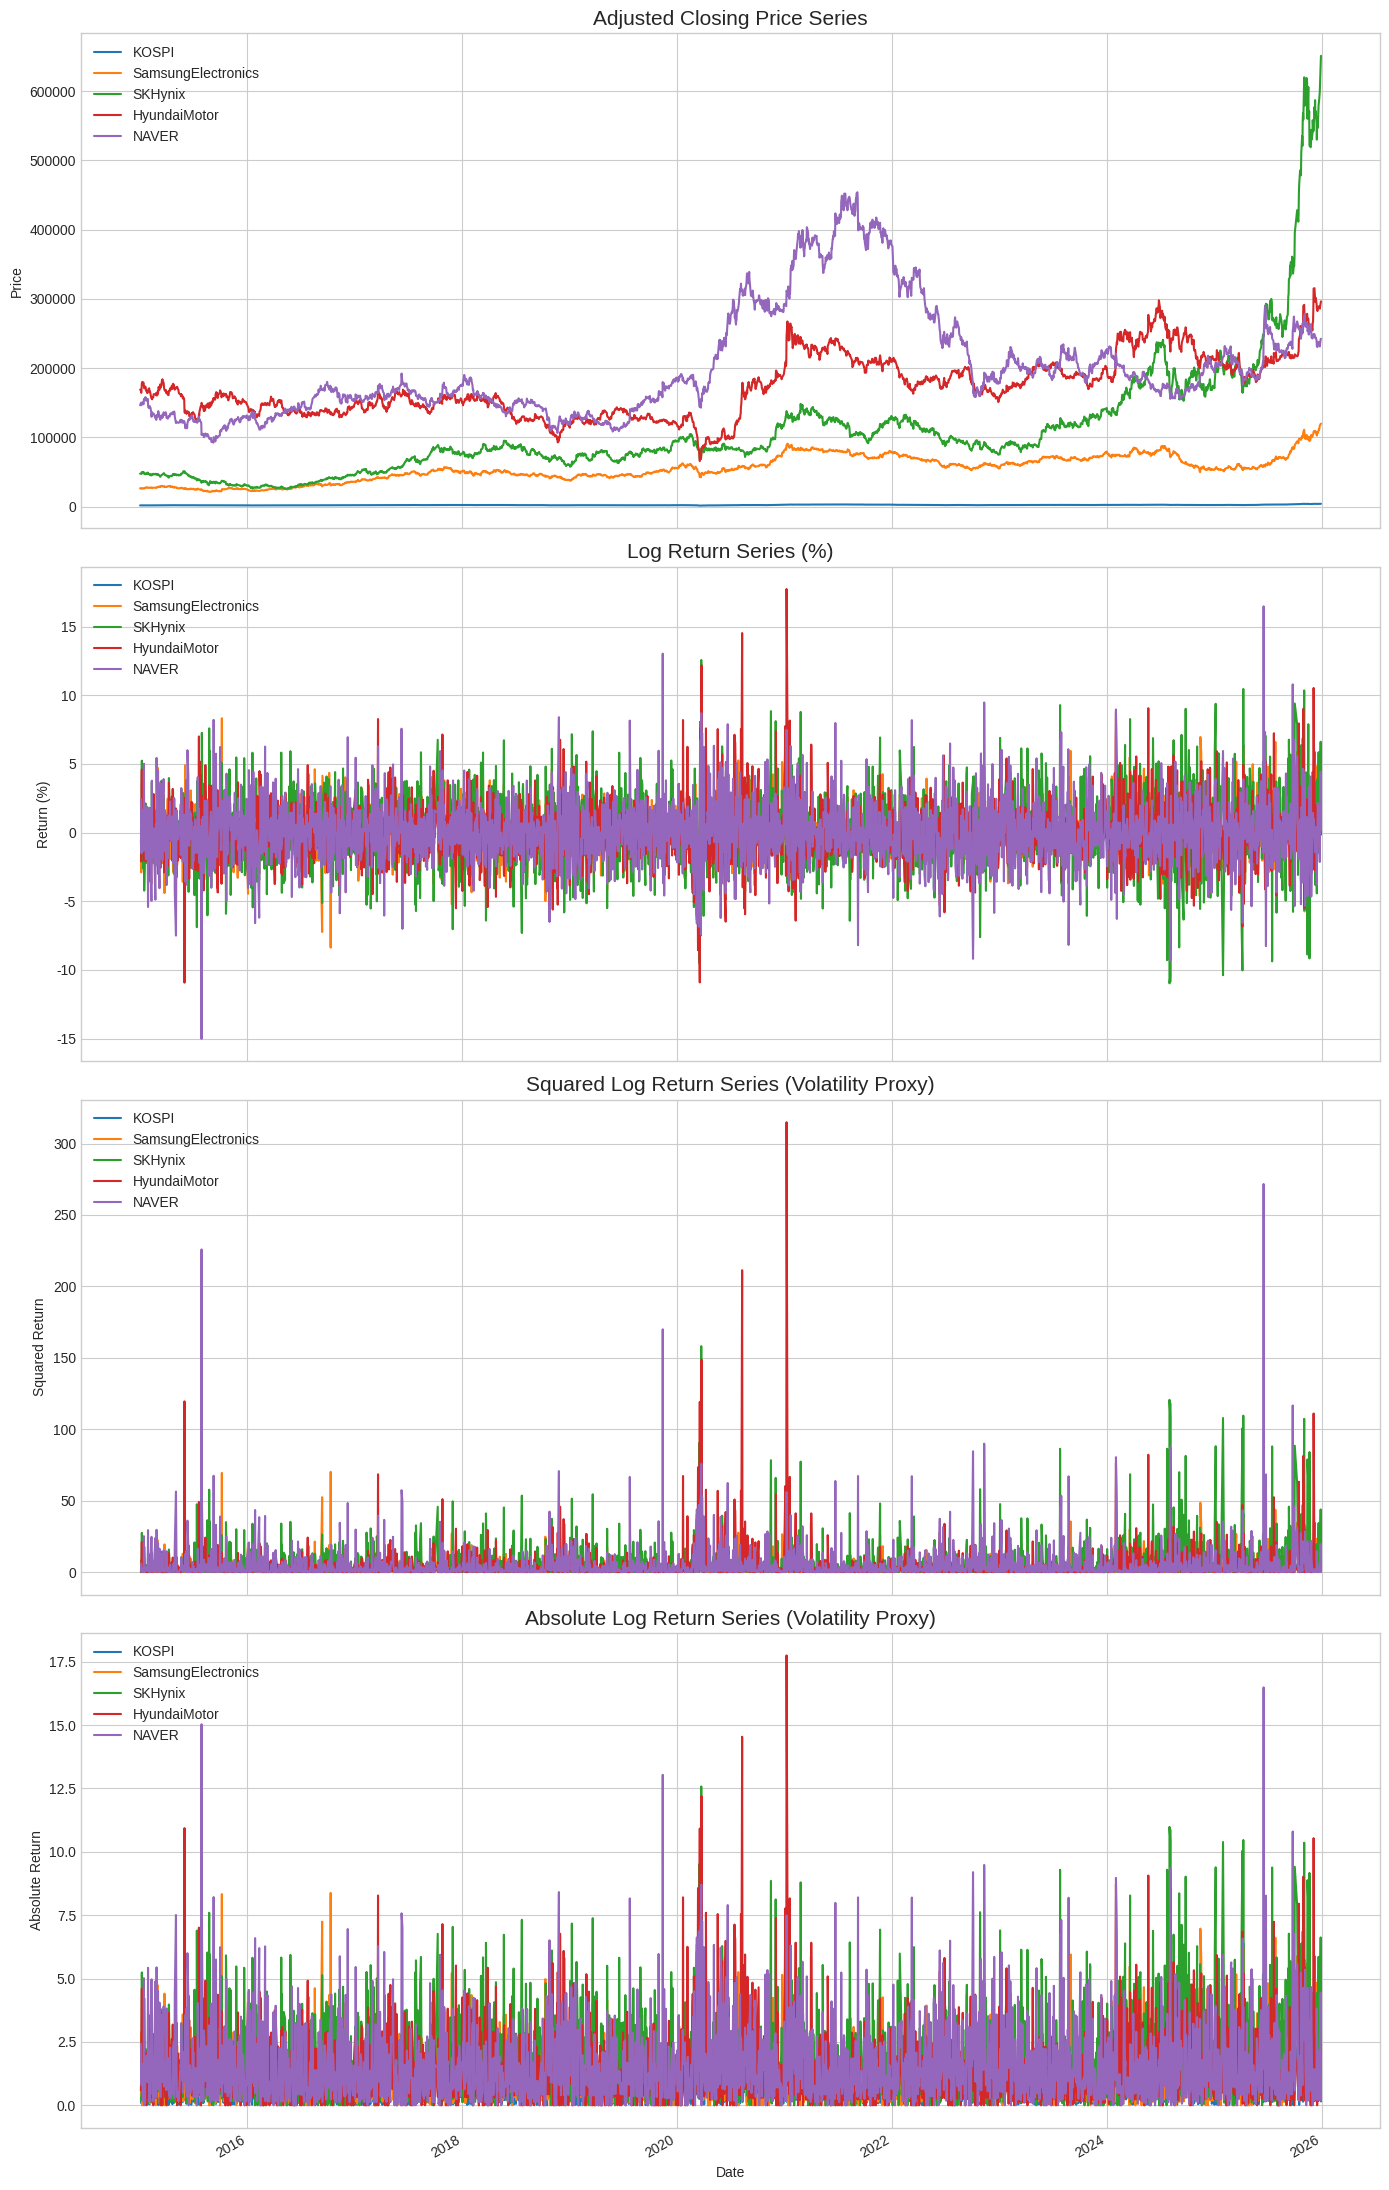

In [4]:
import matplotlib.pyplot as plt

# 그래프 스타일 및 한글 폰트 설정
plt.style.use('seaborn-v0_8-whitegrid')
fig, axes = plt.subplots(4, 1, figsize=(14, 22), sharex=True)

# 1. 가격 시계열 (Price Series)
full_df.plot(ax=axes[0])
axes[0].set_title('Adjusted Closing Price Series', fontsize=15)
axes[0].set_ylabel('Price')
axes[0].legend(loc='upper left')

# 2. 로그수익률 시계열 (Log Return Series)
log_returns.plot(ax=axes[1])
axes[1].set_title('Log Return Series (%)', fontsize=15)
axes[1].set_ylabel('Return (%)')
axes[1].legend(loc='upper left')

# 3. 제곱수익률 시계열 (Squared Return Series - Volatility proxy)
(log_returns**2).plot(ax=axes[2])
axes[2].set_title('Squared Log Return Series (Volatility Proxy)', fontsize=15)
axes[2].set_ylabel('Squared Return')
axes[2].legend(loc='upper left')

# 4. 절댓값 수익률 시계열 (Absolute Return Series - Volatility proxy)
log_returns.abs().plot(ax=axes[3])
axes[3].set_title('Absolute Log Return Series (Volatility Proxy)', fontsize=15)
axes[3].set_ylabel('Absolute Return')
axes[3].legend(loc='upper left')

plt.tight_layout()
plt.show()

# Step 4: 평균, 표준편차, 왜도, 첨도 계산

로그수익률 기술통계량:


,KOSPI,SamsungElectronics,SKHynix,HyundaiMotor,NAVER
mean,0.029003,0.055789,0.096796,0.020828,0.018696
std,1.088652,1.698110,2.465972,2.032482,2.180898
skew,-0.413510,0.105919,0.116992,0.769158,0.372417
kurtosis,7.605296,2.242938,1.590495,5.946170,4.046081



'descriptive_statistics.png' 파일로 저장되었습니다.


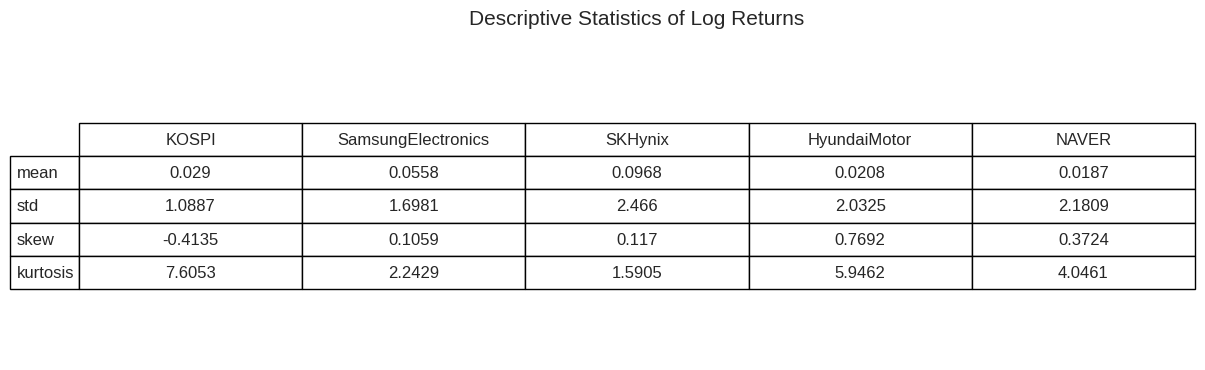

In [5]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. 기초 통계량 계산
stats = log_returns.describe().loc[['mean', 'std']]
stats.loc['skew'] = log_returns.skew()
stats.loc['kurtosis'] = log_returns.kurtosis()

# 결과 출력
print("로그수익률 기술통계량:")
display(stats)

# 2. 통계 표를 PNG 파일로 저장
fig, ax = plt.subplots(figsize=(12, 4))
ax.axis('off')

# matplotlib table 생성
tbl = ax.table(cellText=stats.values.round(4),
               colLabels=stats.columns,
               rowLabels=stats.index,
               loc='center',
               cellLoc='center')

tbl.auto_set_font_size(False)
tbl.set_fontsize(12)
tbl.scale(1.2, 2)

plt.title('Descriptive Statistics of Log Returns', fontsize=15, pad=20)

# 파일 저장
plt.savefig('descriptive_statistics.png', bbox_inches='tight', dpi=300)
print("\n'descriptive_statistics.png' 파일로 저장되었습니다.")
plt.show()

# Step 5: AR(2)-GARCH(1,1) Parameter Estimation


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 981.3/981.3 kB 14.3 MB/s eta 0:00:00

[AR(2)-GARCH(1,1) MLE 파라미터 추정 결과]


,mu (μ),phi1 (φ1),phi2 (φ2),omega (ω),alpha (α),beta (β)
Asset,,,,,,
KOSPI,0.035945,0.019893,0.023042,0.046474,0.131950,0.831211
SamsungElectronics,0.062373,0.027224,-0.047560,0.040569,0.034782,0.951738
SKHynix,0.092535,-0.021922,-0.002040,0.125679,0.034663,0.944542
HyundaiMotor,0.001135,0.022069,-0.031194,0.071874,0.045823,0.937241
NAVER,0.028467,-0.054333,-0.014699,0.730926,0.060181,0.785743


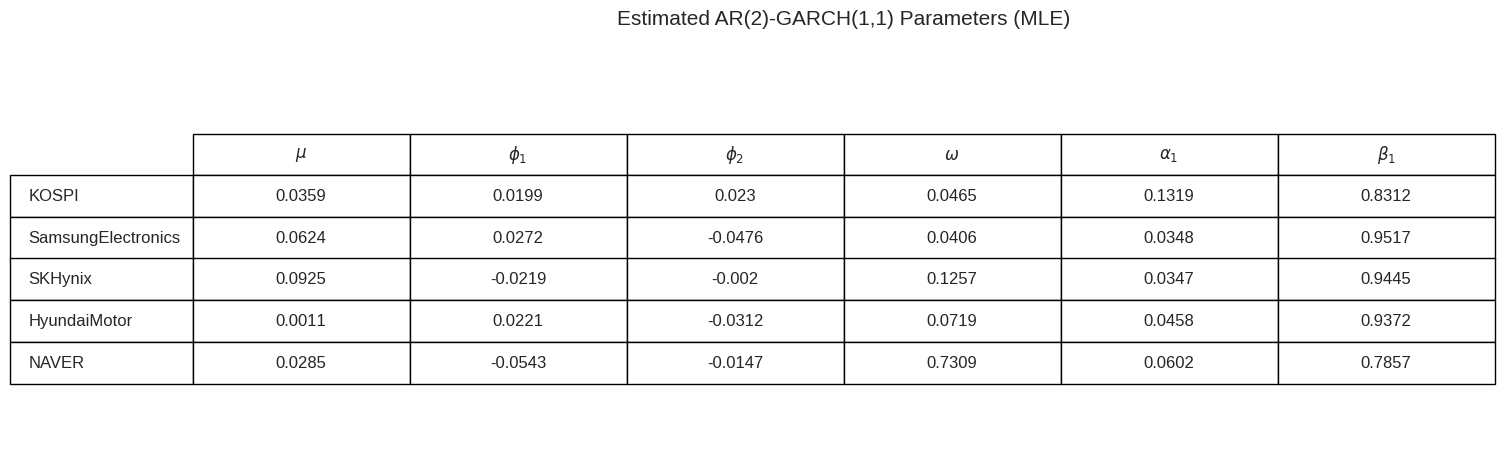

In [6]:
!pip install -q arch

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from arch import arch_model

# 1. 모델 추정 및 결과 저장을 위한 설정
results_dict = {}
params_list = []
asset_names = ['KOSPI', 'SamsungElectronics', 'SKHynix', 'HyundaiMotor', 'NAVER']

# 분석용 데이터 복사
analysis_df = log_returns.copy()

for asset in asset_names:
    # AR(2)-GARCH(1,1) 모형 설정
    model = arch_model(analysis_df[asset], vol='Garch', p=1, q=1, mean='AR', lags=2, dist='normal')

    # MLE 추정 수행
    res = model.fit(disp='off')
    results_dict[asset] = res

    # 파라미터 추출 및 수식 기호 매핑
    p = res.params
    params_list.append({
        'Asset': asset,
        'mu (μ)': p['Const'],
        'phi1 (φ1)': p.filter(like='[1]').iloc[0] if not p.filter(like='[1]').empty else np.nan,
        'phi2 (φ2)': p.filter(like='[2]').iloc[0] if not p.filter(like='[2]').empty else np.nan,
        'omega (ω)': p['omega'],
        'alpha (α)': p['alpha[1]'],
        'beta (β)': p['beta[1]']
    })

    # 2. 조건부 변동성 및 표준화 잔차 계산
    analysis_df[f'{asset}_vol'] = res.conditional_volatility
    analysis_df[f'{asset}_std_res'] = res.resid / res.conditional_volatility

# 3. 파라미터 요약 결과 데이터프레임 생성
summary_df = pd.DataFrame(params_list).set_index('Asset')
print("\n[AR(2)-GARCH(1,1) MLE 파라미터 추정 결과]")
display(summary_df)

# 4. 결과 데이터 확인 (결측치 제거)
final_df = analysis_df.dropna()

# 5. 파라미터 결과 시각화 (수식 기호 포함)
fig, ax = plt.subplots(figsize=(14, 5))
ax.axis('off')

# 컬럼명에 LaTeX 스타일 적용 (raw string r'' 사용)
latex_columns = [r'$\mu$', r'$\phi_1$', r'$\phi_2$', r'$\omega$', r'$\alpha_1$', r'$\beta_1$']

table = ax.table(cellText=summary_df.values.round(4),
                 colLabels=latex_columns,
                 rowLabels=summary_df.index,
                 loc='center', cellLoc='center')

table.auto_set_font_size(False)
table.set_fontsize(12)
table.scale(1.2, 2.5)

plt.title('Estimated AR(2)-GARCH(1,1) Parameters (MLE)', fontsize=15, pad=30)
plt.savefig('garch_parameters_with_symbols.png', bbox_inches='tight', dpi=300)
plt.show()

코드 설명: Parameter 추정


---



1.   MLE 방식을 통해 평균 방정식(AR(2))과 분산 방정식(GARCH(1,1))을 동시에 추정하고
추정된 6개의 핵심 파라미터($\mu, \phi_1, \phi_2, \omega, \alpha, \beta$)를 표 형태로 정리
2.   각 시점의 조건부 변동성($\hat{\sigma}_t$)과 표준화 잔차($z_t$)를 계산하여 기존 데이터프레임에 새로운 열로 추가



# Step 6: AR(2)-GARCH(1,1) 1-step ahead Volatility Forecast



[T+1 시점 (내일) 변동성 예측 결과]
기준 날짜(T): 2025-12-30


,Forecasted Variance (σ²_T+1),Forecasted Volatility (σ_T+1)
Asset,,
KOSPI,1.569753,1.252898
SamsungElectronics,5.732960,2.394360
SKHynix,10.576814,3.252201
HyundaiMotor,6.037188,2.457069
NAVER,4.711086,2.170504


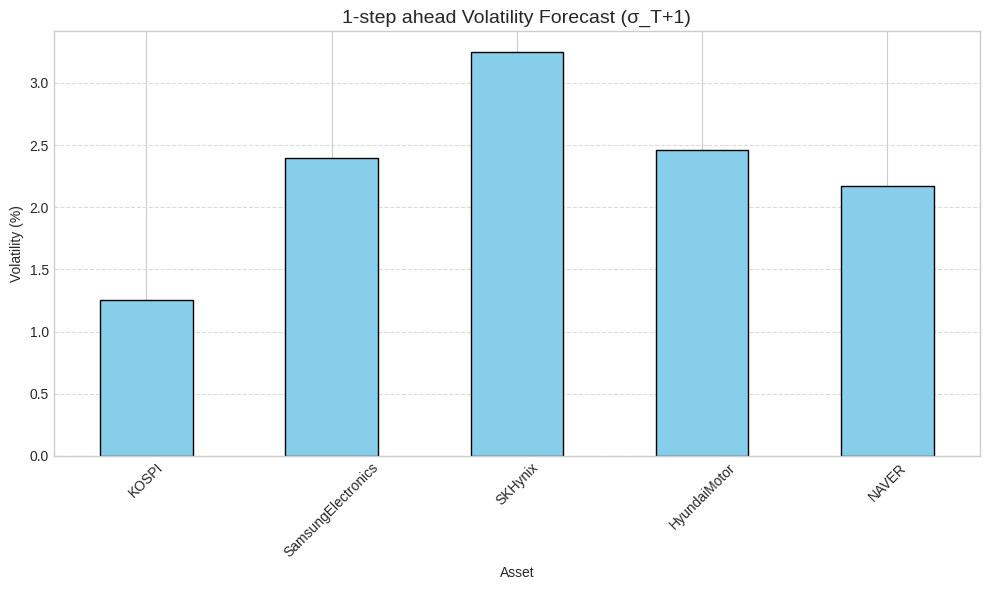

In [7]:
forecasts = []

for asset in asset_names:
    # 각 자산별 추정 결과(results_dict)에서 1-step forecast 수행
    # horizon=1: 바로 다음 시점 예측
    res = results_dict[asset]
    forecast = res.forecast(horizon=1)

    # 예측된 조건부 분산 (sigma^2_{T+1})
    pred_var = forecast.variance.iloc[-1].values[0]

    # 예측된 조건부 변동성 (sigma_{T+1} = sqrt(variance))
    pred_vol = np.sqrt(pred_var)

    forecasts.append({
        'Asset': asset,
        'Forecasted Variance (σ²_T+1)': pred_var,
        'Forecasted Volatility (σ_T+1)': pred_vol
    })

# 결과 데이터프레임 생성
forecast_df = pd.DataFrame(forecasts).set_index('Asset')

print(f"\n[T+1 시점 (내일) 변동성 예측 결과]")
print(f"기준 날짜(T): {log_returns.index[-1].date()}")
display(forecast_df)

# 시각화: 자산별 예상 변동성 비교
plt.figure(figsize=(10, 6))
forecast_df['Forecasted Volatility (σ_T+1)'].plot(kind='bar', color='skyblue', edgecolor='black')
plt.title('1-step ahead Volatility Forecast (σ_T+1)', fontsize=14)
plt.ylabel('Volatility (%)')
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

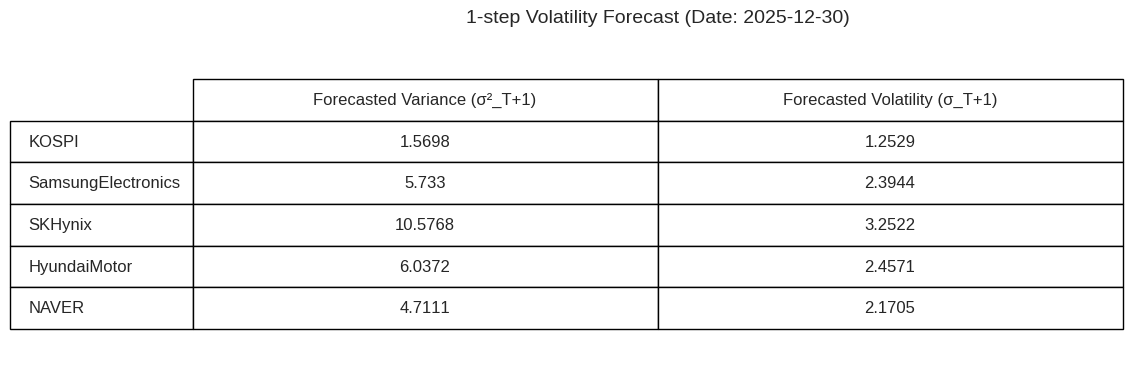

"volatility_forecast.png" 파일을 다운로드합니다...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import matplotlib.pyplot as plt
from google.colab import files

# 1. 시각화 설정 (표 형태로 그리기)
fig, ax = plt.subplots(figsize=(10, 4))
ax.axis('off')

# forecast_df 데이터를 기반으로 table 생성
tbl = ax.table(cellText=forecast_df.values.round(4),
               colLabels=forecast_df.columns,
               rowLabels=forecast_df.index,
               loc='center',
               cellLoc='center')

tbl.auto_set_font_size(False)
tbl.set_fontsize(12)
tbl.scale(1.2, 2.5)

plt.title(f'1-step Volatility Forecast (Date: {log_returns.index[-1].date()})', fontsize=14, pad=20)

# 2. 이미지 파일 저장
output_file = 'volatility_forecast.png'
plt.savefig(output_file, bbox_inches='tight', dpi=300)
plt.show()

# 3. 로컬 PC로 다운로드
print(f'"{output_file}" 파일을 다운로드합니다...')
files.download(output_file)

코드 설명

---

1. `res.forecast(horizon=1)`: 추정된 모델 파라미터와 가장 마지막 관측값($\epsilon_T, \sigma_T$)을 사용하여 $T+1$ 시점의 분산을 계산
2. **변동성 산출**: 예측된 분산값에 제곱근을 취하여 표준편차 단위의 변동성($\sigma_{T+1}$)을 구합니다.
3. **해석**: 이 수치는 내일 수익률이 평균($\mu$)으로부터 위아래로 어느 정도의 변동폭(표준편차)을 가질 것인지에 대한 모델의 예측치입니다.

[자산별 GARCH 잔차 계산 결과]
KOSPI: 잔차 데이터 2697건 계산 완료 (결측치 제외)
SamsungElectronics: 잔차 데이터 2697건 계산 완료 (결측치 제외)
SKHynix: 잔차 데이터 2697건 계산 완료 (결측치 제외)
HyundaiMotor: 잔차 데이터 2697건 계산 완료 (결측치 제외)
NAVER: 잔차 데이터 2697건 계산 완료 (결측치 제외)


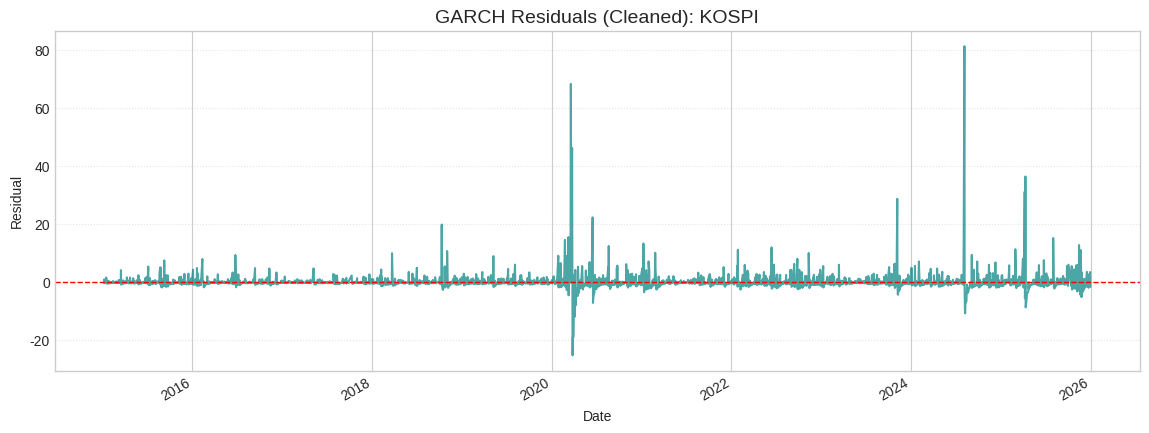


--- KOSPI Residual Data Sample (No NaNs) ---


,0
Date,
2015-01-07,-0.415496
2015-01-08,0.810835
2015-01-09,0.559638
2015-01-12,-0.583484
2015-01-13,-0.533805


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# GARCH 잔차(Actual r^2 - GARCH Variance) 계산
garch_residuals_dict = {}

print("[자산별 GARCH 잔차 계산 결과]")

for asset in asset_names:
    # 1. 실제 제곱수익률 (r_t^2)
    actual_sq_return = final_df[asset]**2

    # 2. GARCH 모델이 추정한 조건부 분산 (sigma_t^2)
    garch_variance = results_dict[asset].conditional_volatility**2

    # 3. 잔차 계산 후 결측치(모델 초기화 구간) 제거
    residual = (actual_sq_return - garch_variance).dropna()

    garch_residuals_dict[asset] = residual
    print(f"{asset}: 잔차 데이터 {len(residual)}건 계산 완료 (결측치 제외)")

# KOSPI 결과 시각화 예시
plt.figure(figsize=(14, 5))
garch_residuals_dict['KOSPI'].plot(alpha=0.7, color='teal')
plt.axhline(0, color='red', linestyle='--', linewidth=1)
plt.title(r'GARCH Residuals (Cleaned): KOSPI', fontsize=14)
plt.ylabel('Residual')
plt.grid(axis='y', linestyle=':', alpha=0.5)
plt.show()

# 결측치가 제거되었는지 확인
print("\n--- KOSPI Residual Data Sample (No NaNs) ---")
display(garch_residuals_dict['KOSPI'].head())

코드설명

---
밑에 Hybrid 모형을 만들기 위해 잔차(Residual) 계산


# Step 7: Deep Learning 모델: 입력변수($X_t$) 모델

In [19]:
from sklearn.preprocessing import StandardScaler
import pandas as pd

# 모든 자산에 대해 데이터를 준비하기 위한 딕셔너리 생성
X_scaled_dict = {}
y_data_dict = {}
scalers_dict = {}

asset_names = ['KOSPI', 'SamsungElectronics', 'SKHynix', 'HyundaiMotor', 'NAVER']

print("[자산별 딥러닝 입력 데이터 구성 현황]")

for asset in asset_names:
    # 1. 입력 변수 (X_t) 구성
    r_t = final_df[asset]            # 로그수익률
    r_t_sq = r_t**2                  # 제곱수익률
    r_t_abs = r_t.abs()              # 절대수익률
    sigma_t = final_df[f'{asset}_vol'] # GARCH 변동성

    # 데이터프레임으로 결합
    X_raw = pd.concat([r_t, r_t_sq, r_t_abs, sigma_t], axis=1)
    X_raw.columns = ['log_return', 'squared_return', 'abs_return', 'garch_vol']

    # 2. 타겟 변수 (y_t) 설정: 내일의 제곱수익률 (r_{t+1}^2)
    y_raw = r_t_sq.shift(-1)

    # 마지막 행 제거 (내일 정답 부재)
    combined_df = pd.concat([X_raw, y_raw.rename('target')], axis=1).dropna()

    X_data = combined_df[['log_return', 'squared_return', 'abs_return', 'garch_vol']]
    y_data = combined_df['target']

    # 3. 데이터 정규화 (Standardization)
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X_data)

    # 결과 저장 (모든 자산이 이 딕셔너리에 저장됩니다)
    X_scaled_dict[asset] = X_scaled
    y_data_dict[asset] = y_data.values
    scalers_dict[asset] = scaler

    print(f"{asset}: X {X_scaled.shape}, y {y_data.shape} 준비 완료")

# 모든 자산의 데이터 샘플 출력
for asset in asset_names:
    print(f"\n--- {asset} 표준화 데이터 샘플 (X_scaled) ---")
    df_sample = pd.DataFrame(X_scaled_dict[asset], columns=['log_return', 'squared_return', 'abs_return', 'garch_vol'])
    display(df_sample.head())

[자산별 딥러닝 입력 데이터 구성 현황]
KOSPI: X (2696, 4), y (2696,) 준비 완료
SamsungElectronics: X (2696, 4), y (2696,) 준비 완료
SKHynix: X (2696, 4), y (2696,) 준비 완료
HyundaiMotor: X (2696, 4), y (2696,) 준비 완료
NAVER: X (2696, 4), y (2696,) 준비 완료

--- KOSPI 표준화 데이터 샘플 (X_scaled) ---


,log_return,squared_return,abs_return,garch_vol
0,0.039813,-0.322254,-0.890891,-0.928439
1,0.982300,0.006135,0.431777,-0.974735
2,0.934573,-0.024307,0.364798,-0.717686
3,-0.206691,-0.313335,-0.733923,-0.578262
4,-0.209917,-0.312958,-0.729396,-0.656641



--- SamsungElectronics 표준화 데이터 샘플 (X_scaled) ---


,log_return,squared_return,abs_return,garch_vol
0,0.509876,-0.342133,-0.297520,-1.590249
1,0.281210,-0.437205,-0.638605,-1.586187
2,-0.033406,-0.485176,-1.107895,-1.621726
3,0.056176,-0.481287,-0.974271,-1.660530
4,0.987117,0.019556,0.414344,-1.697212



--- SKHynix 표준화 데이터 샘플 (X_scaled) ---


,log_return,squared_return,abs_return,garch_vol
0,-0.124546,-0.523550,-0.998846,-0.724889
1,2.085223,1.848984,2.071573,-0.800974
2,-0.242523,-0.505605,-0.821183,-0.335695
3,0.447383,-0.402764,-0.394891,-0.425228
4,-1.100651,0.066004,0.471094,-0.491109



--- HyundaiMotor 표준화 데이터 샘플 (X_scaled) ---


,log_return,squared_return,abs_return,garch_vol
0,1.607376,0.573210,1.288170,-0.034929
1,2.251704,1.459138,2.199914,0.131775
2,0.539113,-0.247326,-0.223457,0.468797
3,-0.698627,-0.186631,-0.027638,0.388590
4,0.540653,-0.246726,-0.221278,0.320395



--- NAVER 표준화 데이터 샘플 (X_scaled) ---


,log_return,squared_return,abs_return,garch_vol
0,-0.692381,-0.216345,-0.051586,0.176180
1,0.737419,-0.180545,0.037128,0.021588
2,0.482000,-0.308910,-0.330854,-0.105802
3,-0.130193,-0.400601,-0.861527,-0.265395
4,-0.623729,-0.252623,-0.150493,-0.460627


코드 설명


---
각 변수(수익률, 제곱수익률, GARCH 변동성 등)를 하나의 테이블로 합침(열(Column) 옆으로 계속 이어 붙여서)

1. **변수선택**: 로그수익률($r_t$), 제곱수익률($r_t^2$), 절대수익률($|r_t|$), GARCH 추정값($\hat{\sigma}_t$) 사용
2. **행렬 구성**: 각 날짜($t$)마다 1개의 숫자가 아닌, 4개의 숫자가 들어있는 벡터가 생성


# Step 8: Deep Learning 모델: 3차원 텐서 구성

In [20]:
import numpy as np
import pandas as pd

# 1. 3차원 텐서 변환 함수 정의
def create_3d_tensor(X_data, y_data, window_size=30):
    X_3d, y_3d = [], []
    for i in range(len(X_data) - window_size):
        X_3d.append(X_data[i : i + window_size])
        y_3d.append(y_data[i + window_size])
    return np.array(X_3d), np.array(y_3d).reshape(-1, 1)

# 2. 모든 자산에 대해 3차원 텐서 구축 및 저장
window_size = 30
asset_names = ['KOSPI', 'SamsungElectronics', 'SKHynix', 'HyundaiMotor', 'NAVER']

X_3d_dict = {}
y_3d_dict = {}

print("[자산별 3차원 텐서 구축 현황]")
for asset in asset_names:
    X_3d_asset, y_3d_asset = create_3d_tensor(X_scaled_dict[asset], y_data_dict[asset], window_size)
    X_3d_dict[asset] = X_3d_asset
    y_3d_dict[asset] = y_3d_asset
    print(f"{asset}: X {X_3d_asset.shape}, y {y_3d_asset.shape} 완료")

# 3. KOSPI 데이터를 기준으로 시각화 예시 출력
# (이후 학습 단계에서 사용할 변수 X_3d, y_3d 기본값 설정)
X_3d, y_3d = X_3d_dict['KOSPI'], y_3d_dict['KOSPI']

feature_names = ['log_return', 'squared_return', 'abs_return', 'garch_vol']

def display_slice(tensor, sample_idx, title):
    print(f"\n[{title}]: 샘플 {sample_idx+1} ({sample_idx+1}일차~{sample_idx+window_size}일차 데이터)")
    df_slice = pd.DataFrame(tensor[sample_idx], columns=feature_names)
    display(df_slice.head(5))
    print("...")
    display(df_slice.tail(5))

display_slice(X_3d, 0, "KOSPI 데이터 텐서 예시 (제1장)")

print("\n" + "="*50)
print(f"전체 {len(asset_names)}개 자산에 대한 3차원 데이터 구축이 완료되었습니다.")

[자산별 3차원 텐서 구축 현황]
KOSPI: X (2666, 30, 4), y (2666, 1) 완료
SamsungElectronics: X (2666, 30, 4), y (2666, 1) 완료
SKHynix: X (2666, 30, 4), y (2666, 1) 완료
HyundaiMotor: X (2666, 30, 4), y (2666, 1) 완료
NAVER: X (2666, 30, 4), y (2666, 1) 완료

[KOSPI 데이터 텐서 예시 (제1장)]: 샘플 1 (1일차~30일차 데이터)


,log_return,squared_return,abs_return,garch_vol
0,0.039813,-0.322254,-0.890891,-0.928439
1,0.982300,0.006135,0.431777,-0.974735
2,0.934573,-0.024307,0.364798,-0.717686
3,-0.206691,-0.313335,-0.733923,-0.578262
4,-0.209917,-0.312958,-0.729396,-0.656641


...


,log_return,squared_return,abs_return,garch_vol
25,0.438298,-0.253532,-0.331665,-0.865803
26,-0.219896,-0.311748,-0.715391,-0.862321
27,0.720368,-0.142792,0.064186,-0.905051
28,0.006741,-0.323341,-0.937303,-0.809257
29,0.123434,-0.316350,-0.773539,-0.874109



전체 5개 자산에 대한 3차원 데이터 구축이 완료되었습니다.


# Step 9: Deep Learning 모델: LSTM 모델 학습

전체 5개 자산에 대해 LSTM 학습을 시작합니다...

>>> KOSPI 모델 학습 중...
84/84 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step
KOSPI 학습 완료.

>>> SamsungElectronics 모델 학습 중...
84/84 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step
SamsungElectronics 학습 완료.

>>> SKHynix 모델 학습 중...
84/84 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step
SKHynix 학습 완료.

>>> HyundaiMotor 모델 학습 중...
84/84 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step
HyundaiMotor 학습 완료.

>>> NAVER 모델 학습 중...
84/84 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step
NAVER 학습 완료.


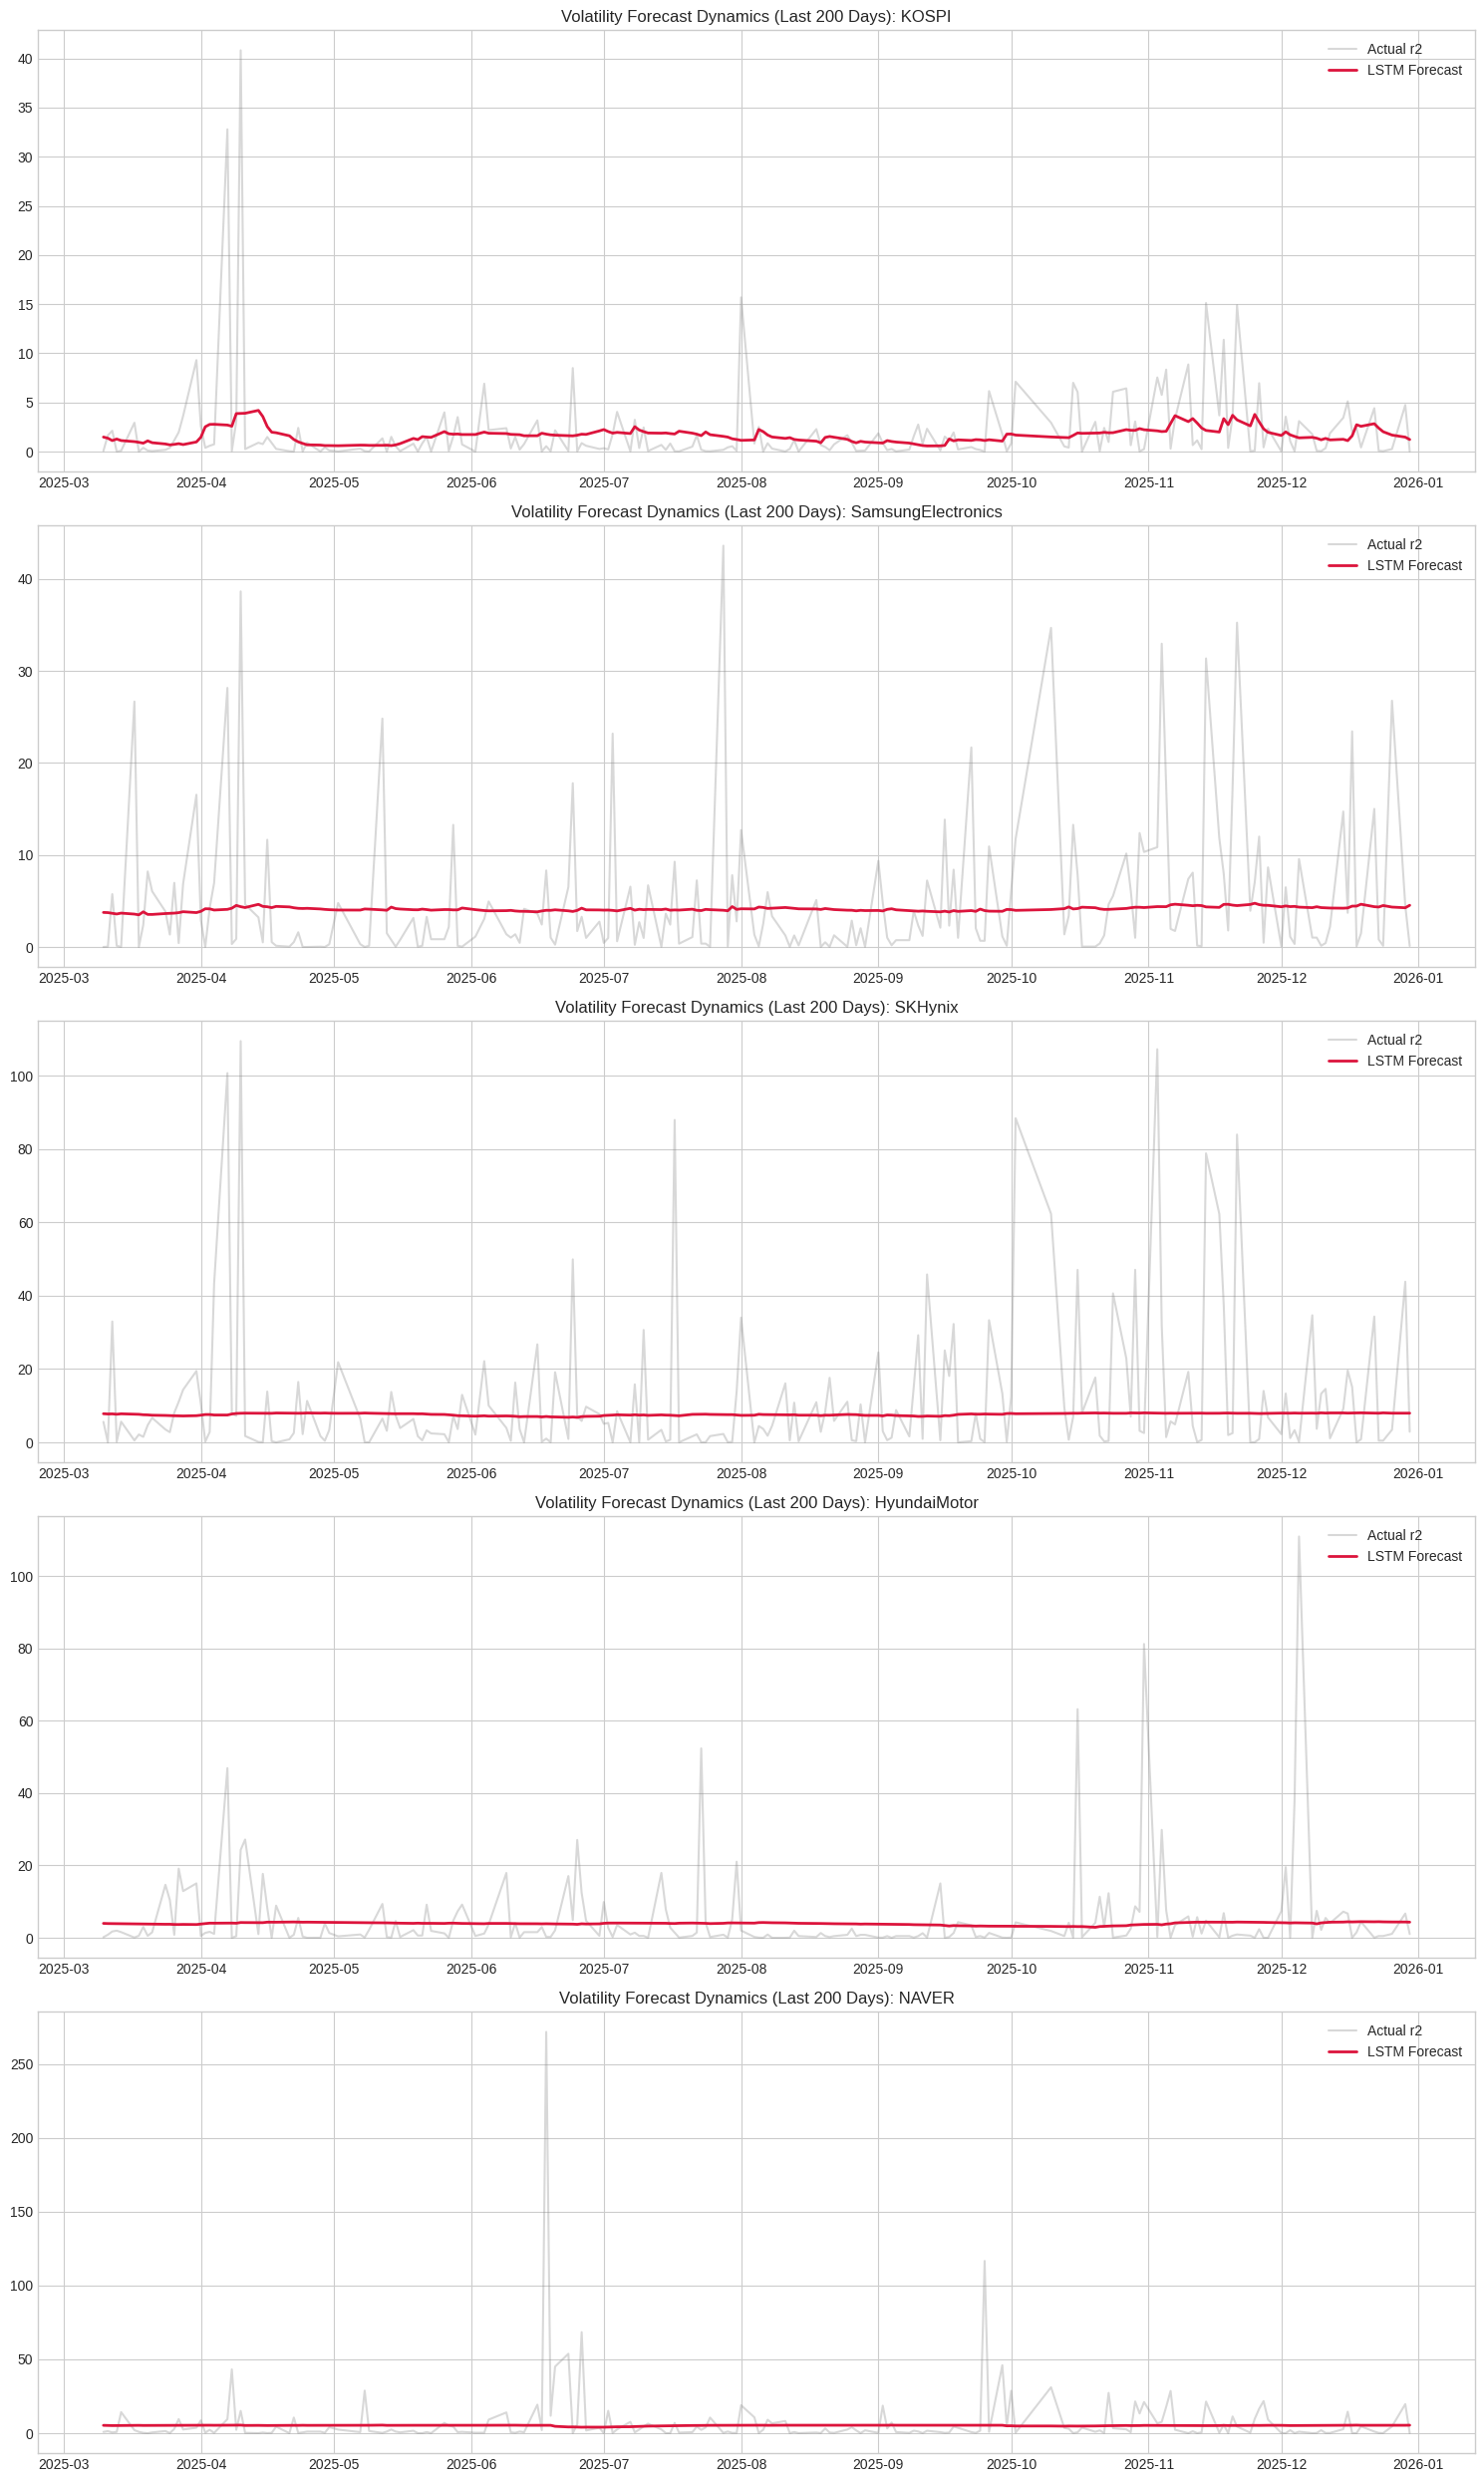

In [21]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Input
from tensorflow.keras.callbacks import EarlyStopping
import tensorflow.keras.backend as K
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler

# 1. 수치적으로 안정적인 QLIKE 손실 함수 정의
def robust_qlike_loss(y_true, y_pred):
    epsilon = 1e-6
    y_true = K.maximum(y_true, epsilon)
    y_pred = K.maximum(y_pred, epsilon)
    return K.mean(y_true / y_pred - K.log(y_true / y_pred) - 1)

# 2. 데이터 준비 (Step 7 & 8 로직 포함)
asset_names = ['KOSPI', 'SamsungElectronics', 'SKHynix', 'HyundaiMotor', 'NAVER']
window_size = 30
X_3d_dict = {}
y_3d_dict = {}

for asset in asset_names:
    r_t = final_df[asset]
    r_t_sq = r_t**2
    r_t_abs = r_t.abs()
    sigma_t = final_df[f'{asset}_vol']
    X_raw = pd.DataFrame({'r': r_t, 'r2': r_t_sq, 'abs': r_t_abs, 'vol': sigma_t})
    y_raw = r_t_sq.shift(-1)
    combined = pd.concat([X_raw, y_raw.rename('target')], axis=1).dropna()

    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(combined[['r', 'r2', 'abs', 'vol']])
    y_vals = combined['target'].values

    X_3d, y_3d = [], []
    for i in range(len(X_scaled) - window_size):
        X_3d.append(X_scaled[i : i + window_size])
        y_3d.append(y_vals[i + window_size])
    X_3d_dict[asset], y_3d_dict[asset] = np.array(X_3d), np.array(y_3d).reshape(-1, 1)

# 3. 모든 자산에 대해 순차적으로 학습 진행
lstm_models = {}
lstm_preds = {}

print("전체 5개 자산에 대해 LSTM 학습을 시작합니다...")

for asset in asset_names:
    print(f"\n>>> {asset} 모델 학습 중...")
    X_curr, y_curr = X_3d_dict[asset], y_3d_dict[asset]
    input_shape = (X_curr.shape[1], X_curr.shape[2])

    model = Sequential([
        Input(shape=input_shape),
        LSTM(64, activation='tanh'),
        Dense(1, activation='softplus')
    ])

    model.compile(optimizer='adam', loss=robust_qlike_loss)
    early_stop = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)
    model.fit(X_curr, y_curr, epochs=30, batch_size=64, validation_split=0.1, callbacks=[early_stop], verbose=0)

    lstm_models[asset] = model
    lstm_preds[asset] = model.predict(X_curr)
    print(f"{asset} 학습 완료.")

# 4. 결과 시각화
fig, axes = plt.subplots(len(asset_names), 1, figsize=(15, 25))
for i, asset in enumerate(asset_names):
    y_actual = y_3d_dict[asset].flatten()
    y_pred = lstm_preds[asset].flatten()
    dates = final_df.index[-len(y_actual):]
    axes[i].plot(dates[-200:], y_actual[-200:], label='Actual r2', color='gray', alpha=0.3)
    axes[i].plot(dates[-200:], y_pred[-200:], label='LSTM Forecast', color='crimson', linewidth=2)
    axes[i].set_title(f'Volatility Forecast Dynamics (Last 200 Days): {asset}')
    axes[i].legend()
plt.tight_layout()
plt.show()

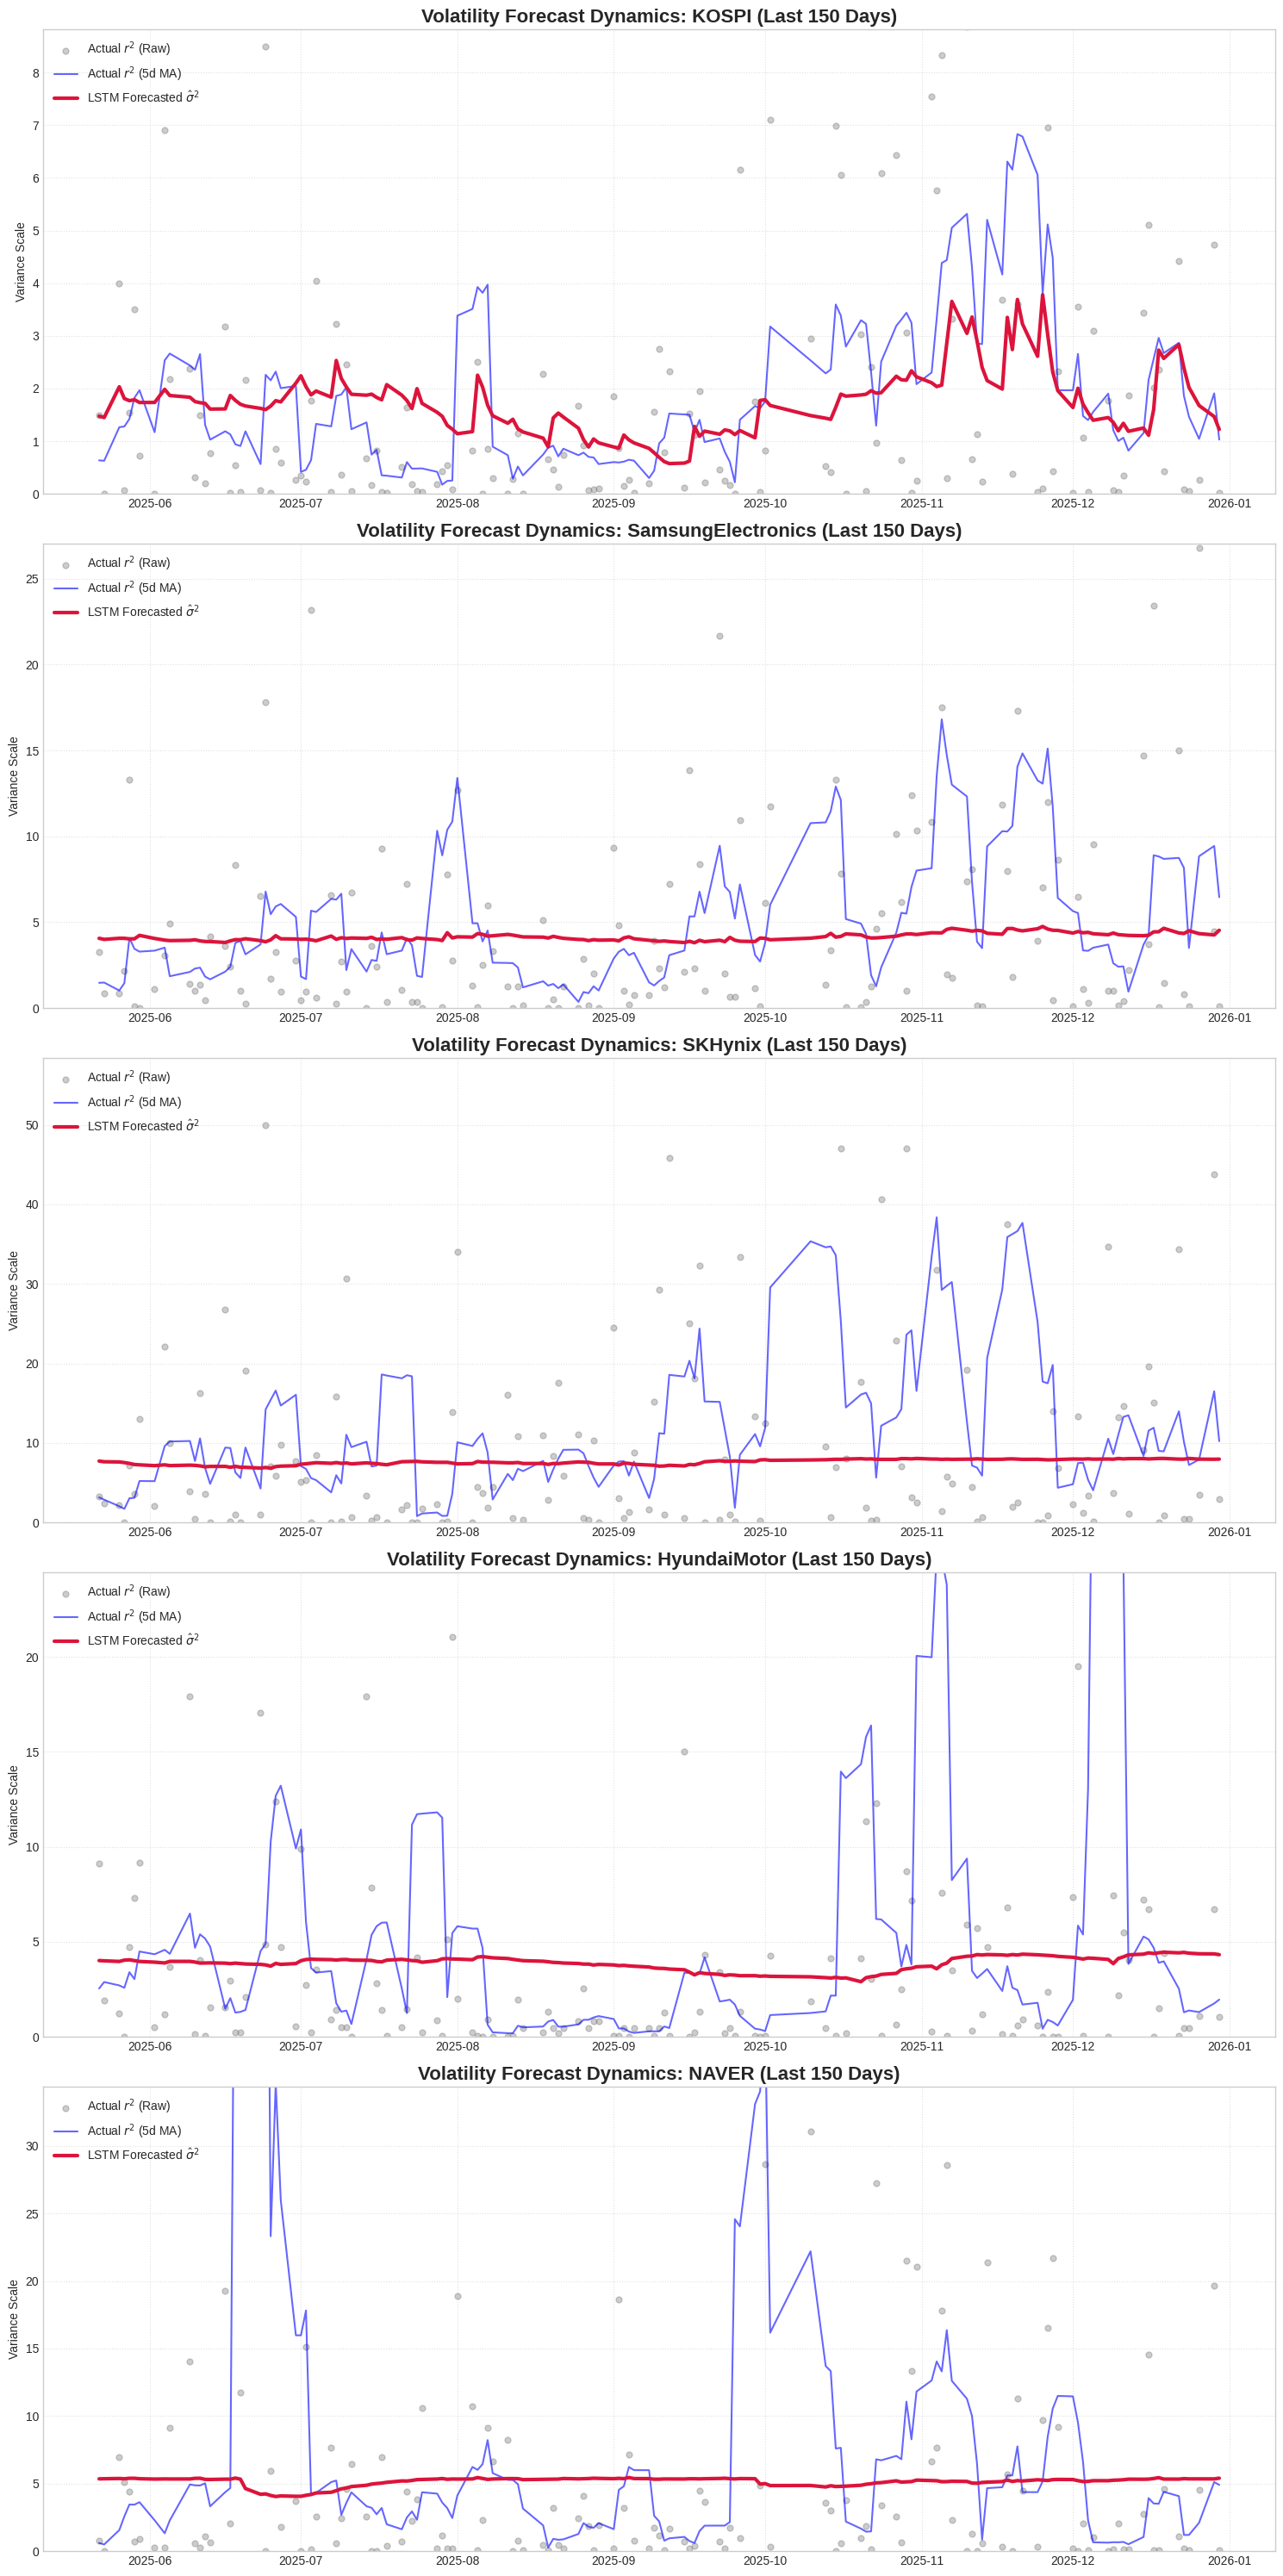

In [22]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# 전체 5개 자산 리스트
all_assets = ['KOSPI', 'SamsungElectronics', 'SKHynix', 'HyundaiMotor', 'NAVER']

# 5행 1열 서브플롯 생성
fig, axes = plt.subplots(5, 1, figsize=(15, 30))
zoom_days = 150  # 최근 150일 데이터 시각화

for i, asset in enumerate(all_assets):
    # 데이터 준비
    y_actual = y_3d_dict[asset].flatten()
    y_pred = lstm_preds[asset].flatten()
    dates = final_df.index[-len(y_actual):]

    # 5일 이동평균 계산
    actual_series = pd.Series(y_actual, index=dates)
    actual_ma = actual_series.rolling(window=5).mean()

    ax = axes[i]

    # 1. 실제 제곱수익률 (Raw - 더 진하고 크게 조정)
    ax.scatter(dates[-zoom_days:], y_actual[-zoom_days:], color='gray', alpha=0.4, s=25, label='Actual $r^2$ (Raw)')
    # 2. 실제 제곱수익률 (5일 이동평균 - 추세)
    ax.plot(dates[-zoom_days:], actual_ma[-zoom_days:], color='blue', alpha=0.6, label='Actual $r^2$ (5d MA)')
    # 3. LSTM 모델 예측값
    ax.plot(dates[-zoom_days:], y_pred[-zoom_days:], color='crimson', linewidth=3, label=r'LSTM Forecasted $\hat{\sigma}^2$')

    # 그래프 설정
    ax.set_title(f'Volatility Forecast Dynamics: {asset} (Last {zoom_days} Days)', fontsize=16, fontweight='bold')
    ax.set_ylabel('Variance Scale')
    ax.legend(loc='upper left')
    ax.grid(True, linestyle=':', alpha=0.6)

    # Y축 범위를 조금 더 넉넉하게 조정 (실제값의 90% 정도가 포함되도록)
    y_upper_limit = np.percentile(y_actual[-zoom_days:], 95) * 1.2
    ax.set_ylim(0, y_upper_limit)

plt.tight_layout()
plt.show()

# Step 9: Hybrid 모델: LSTM 모형 재정비





In [23]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Input
from tensorflow.keras.callbacks import EarlyStopping
import numpy as np
import pandas as pd

# 1. 하이브리드용 정답 데이터(y) 재구성: [내일의 제곱수익률 - GARCH의 내일 예측값]
y_hybrid_dict = {}

print("[하이브리드 모델용 타겟 데이터(오차) 구성]")
for asset in asset_names:
    # 실제 내일의 제곱수익률 (Step 8에서 구축됨)
    y_actual = y_3d_dict[asset]

    # GARCH 조건부 분산 (Step 5에서 계산된 volatility를 분산으로 변환)
    garch_vol = final_df[f'{asset}_vol'].values
    # 3D 텐서 구축 시 window_size(30)만큼 앞부분이 제외되므로 인덱스를 맞춤
    garch_var_matched = (garch_vol[window_size : window_size + len(y_actual)]**2).reshape(-1, 1)

    # 타겟 설정: 실제값 - GARCH 예측값
    y_residual = y_actual - garch_var_matched
    y_hybrid_dict[asset] = y_residual

    print(f"{asset}: 오차 타겟 데이터 {y_residual.shape} 생성 완료")

# 2. LSTM 모델 재학습 (오차 예측)
lstm_hybrid_models = {}
lstm_residual_preds = {}

print("\n[Hybrid LSTM 모델 재학습 시작...]")

for asset in asset_names:
    print(f">>> {asset} 오차 학습 중...")

    X_curr = X_3d_dict[asset]
    y_curr = y_hybrid_dict[asset]

    # 모델 아키텍처 (기존 뼈대 유지)
    model = Sequential([
        Input(shape=(X_curr.shape[1], X_curr.shape[2])),
        LSTM(64, activation='tanh'),
        Dense(1) # 오차는 음수일 수 있으므로 linear activation 사용
    ])

    model.compile(optimizer='adam', loss='mse') # 오차 학습에는 MSE가 적합
    early_stop = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)

    # 가중치 재학습
    model.fit(X_curr, y_curr, epochs=20, batch_size=64, validation_split=0.1, callbacks=[early_stop], verbose=0)

    lstm_hybrid_models[asset] = model
    lstm_residual_preds[asset] = model.predict(X_curr)
    print(f"{asset} 재학습 완료.")

# 3. 학습된 비선형 오차(e_hat) 예측값 표로 정리
print("\n[자산별 최근 비선형 오차 예측값 (e_hat) 요약]")
residual_summary = pd.DataFrame({
    asset: lstm_residual_preds[asset].flatten()
    for asset in asset_names
}, index=final_df.index[-len(lstm_residual_preds['KOSPI']):])

display(residual_summary.tail())

[하이브리드 모델용 타겟 데이터(오차) 구성]
KOSPI: 오차 타겟 데이터 (2666, 1) 생성 완료
SamsungElectronics: 오차 타겟 데이터 (2666, 1) 생성 완료
SKHynix: 오차 타겟 데이터 (2666, 1) 생성 완료
HyundaiMotor: 오차 타겟 데이터 (2666, 1) 생성 완료
NAVER: 오차 타겟 데이터 (2666, 1) 생성 완료

[Hybrid LSTM 모델 재학습 시작...]
>>> KOSPI 오차 학습 중...
84/84 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step
KOSPI 재학습 완료.
>>> SamsungElectronics 오차 학습 중...
84/84 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step
SamsungElectronics 재학습 완료.
>>> SKHynix 오차 학습 중...
84/84 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step
SKHynix 재학습 완료.
>>> HyundaiMotor 오차 학습 중...
84/84 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step
HyundaiMotor 재학습 완료.
>>> NAVER 오차 학습 중...
84/84 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step
NAVER 재학습 완료.

[자산별 최근 비선형 오차 예측값 (e_hat) 요약]


,KOSPI,SamsungElectronics,SKHynix,HyundaiMotor,NAVER
Date,,,,,
2025-12-23,0.075250,-1.040988,-0.447572,-2.355155,-0.078815
2025-12-24,-0.314887,-1.004122,-0.631696,-2.361787,-0.116600
2025-12-26,-0.219779,-1.121324,-0.585884,-2.263477,-0.109549
2025-12-29,-0.080262,-1.144066,-0.614230,-2.122631,-0.108437
2025-12-30,-0.047781,-1.041795,-0.724633,-1.970594,-0.086602


코드 설명


---

하이브리드 모델을 만들기 위해서 잔차를 계산하는 deep learning LSTM 모델을 새로 구성. 그전에는 제곱수익률이 타겟 변수(y) 였음으로 여기에서는 비선형 오차($\hat{e}_{t+1}$)로 y를 바꿔줌, 또한 변동성 자체를 예측할 때는 QLIKE가 유리하지만, '오차의 크기'를 줄이는 단계에서는 표준적인 MSE(Mean Squared Error)가 더 적합하여 손실함수에 이를 적용


# Step 9: Hybrid 모델 구성

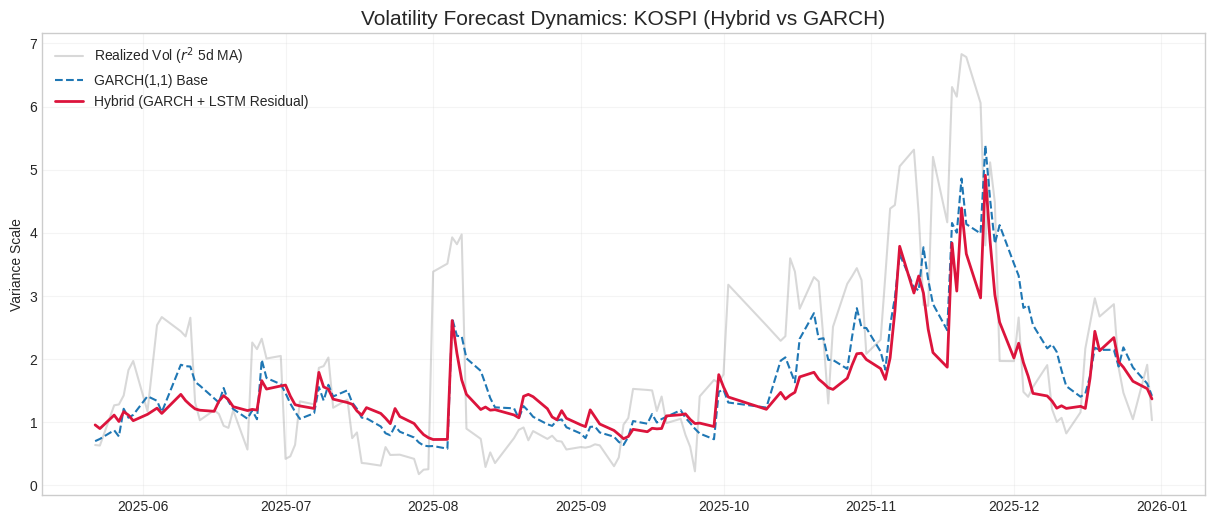

In [24]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 1. 하이브리드 결합 모델 구성 및 시각화 (모든 자산 대상)
all_hybrid_results = {}

for asset in asset_names:
    # 실제 타겟 (내일의 제곱수익률)
    y_actual = y_3d_dict[asset].flatten()

    # GARCH의 기본 예측값 (분산)
    garch_vol = final_df[f'{asset}_vol'].values
    garch_var_matched = (garch_vol[window_size : window_size + len(y_actual)]**2)

    # LSTM이 예측한 비선형 오차 (e_hat)
    lstm_err_correction = lstm_residual_preds[asset].flatten()

    # 최종 하이브리드 예측 결합: GARCH + LSTM Residual
    # 분산은 항상 0보다 커야 하므로 하한선(epsilon) 설정
    hybrid_var = np.maximum(garch_var_matched + lstm_err_correction, 1e-6)
    all_hybrid_results[asset] = hybrid_var

# 2. KOSPI 기준 하이브리드 효과 시각화 (최근 150일)
plt.figure(figsize=(15, 6))
asset_plot = 'KOSPI'
y_actual_plot = y_3d_dict[asset_plot].flatten()
dates = final_df.index[-len(y_actual_plot):]

# 실제값 노이즈 제거를 위한 5일 이동평균
actual_ma = pd.Series(y_actual_plot, index=dates).rolling(5).mean()

garch_vol_plot = final_df[f'{asset_plot}_vol'].values
garch_var_plot = (garch_vol_plot[window_size : window_size + len(y_actual_plot)]**2)

plt.plot(dates[-150:], actual_ma[-150:], label='Realized Vol ($r^2$ 5d MA)', color='gray', alpha=0.3)
plt.plot(dates[-150:], garch_var_plot[-150:], label='GARCH(1,1) Base', linestyle='--')
plt.plot(dates[-150:], all_hybrid_results[asset_plot][-150:], label='Hybrid (GARCH + LSTM Residual)', color='crimson', linewidth=2)

plt.title(f'Volatility Forecast Dynamics: {asset_plot} (Hybrid vs GARCH)', fontsize=15)
plt.ylabel('Variance Scale')
plt.legend()
plt.grid(True, alpha=0.2)
plt.show()

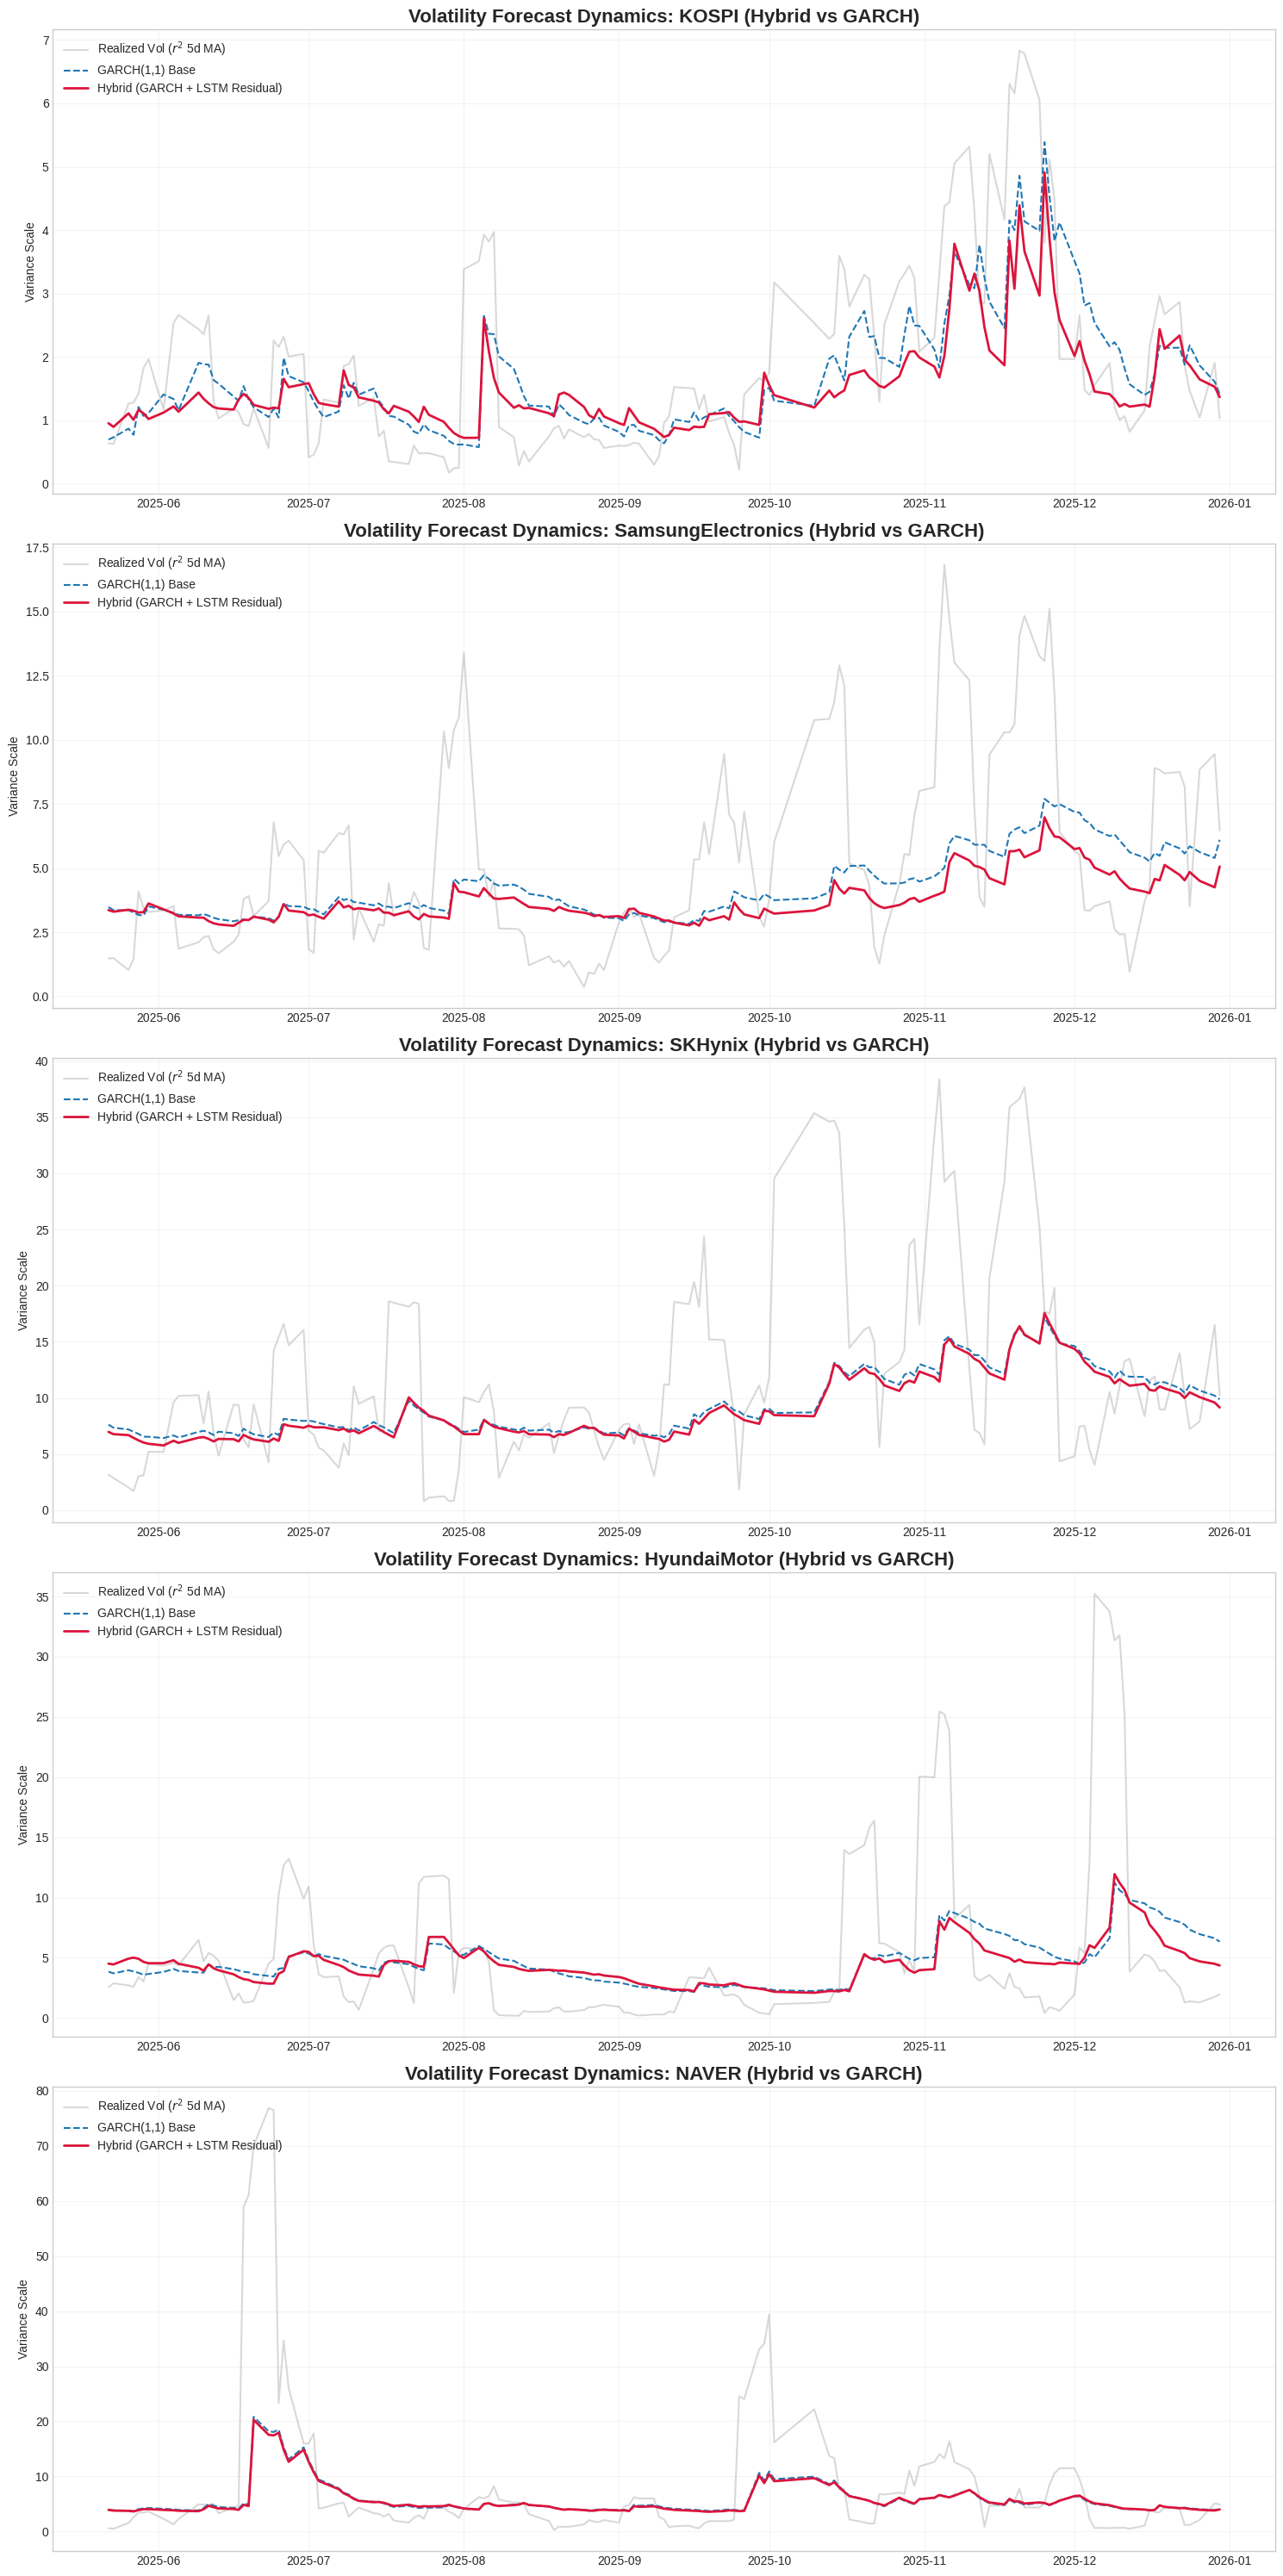

In [25]:
# 전체 5개 자산에 대한 Hybrid 모델 시각화 (KOSPI 포함)
all_assets = ['KOSPI', 'SamsungElectronics', 'SKHynix', 'HyundaiMotor', 'NAVER']

fig, axes = plt.subplots(5, 1, figsize=(15, 30))
zoom_days = 150

for i, asset in enumerate(all_assets):
    # 1. 실제 타겟 (내일의 제곱수익률)
    y_act = y_3d_dict[asset].flatten()

    # 2. GARCH의 기본 예측값 (분산)
    g_vol = final_df[f'{asset}_vol'].values
    g_var = (g_vol[window_size : window_size + len(y_act)]**2)

    # 3. LSTM이 예측한 비선형 오차 (e_hat)
    l_err = lstm_residual_preds[asset].flatten()

    # 4. 최종 하이브리드 예측 결합
    h_var = np.maximum(g_var + l_err, 1e-6)

    # 날짜 및 이동평균 계산
    dates = final_df.index[-len(y_act):]
    act_ma = pd.Series(y_act, index=dates).rolling(window=5).mean()

    # 그래프 그리기
    ax = axes[i]
    ax.plot(dates[-zoom_days:], act_ma[-zoom_days:], label='Realized Vol ($r^2$ 5d MA)', color='gray', alpha=0.3)
    ax.plot(dates[-zoom_days:], g_var[-zoom_days:], label='GARCH(1,1) Base', linestyle='--')
    ax.plot(dates[-zoom_days:], h_var[-zoom_days:], label='Hybrid (GARCH + LSTM Residual)', color='crimson', linewidth=2)

    ax.set_title(f'Volatility Forecast Dynamics: {asset} (Hybrid vs GARCH)', fontsize=16, fontweight='bold')
    ax.set_ylabel('Variance Scale')
    ax.legend(loc='upper left')
    ax.grid(True, alpha=0.2)

plt.tight_layout()
plt.show()

코드 설명


---
$$\hat{\sigma}_{t+1}^2 = \sigma_{t+1, GARCH}^2 + \hat{e}_{t+1}$$

GARCH를 베이스라인으로 깔고, 딥러닝이 그 오차(Residual)만 맞추는 방식으로 Hybrid 모형 구성

# Step 10: 예측 성능 평가

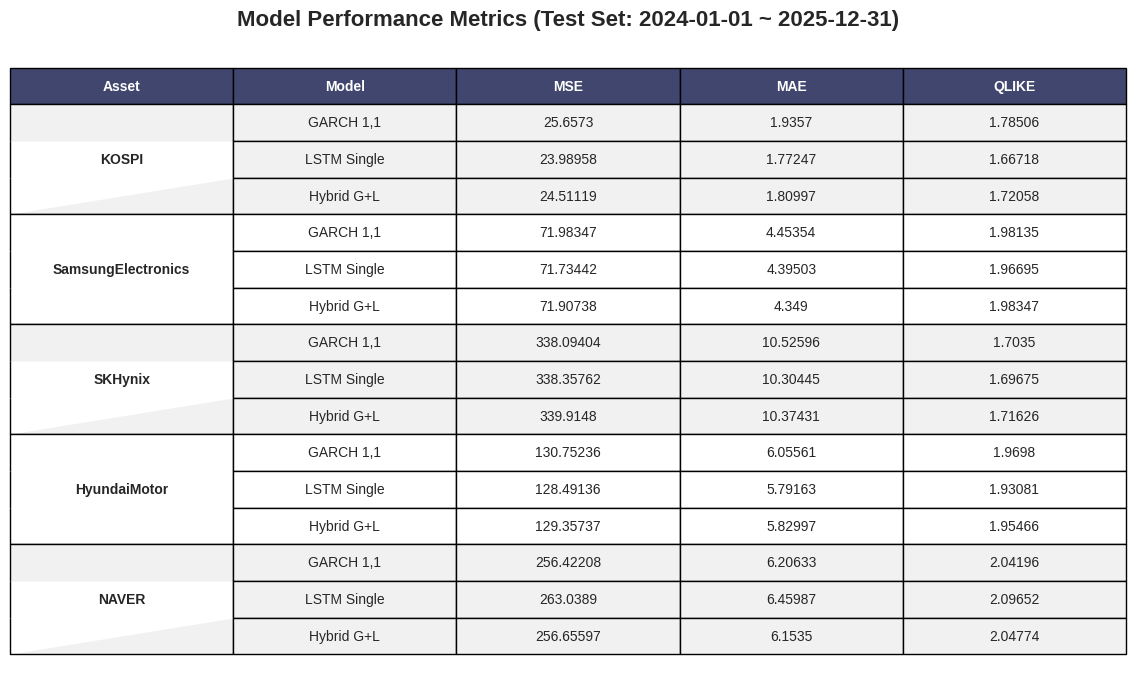

'test_performance_summary.png' (평가구간 2024-01-01~2025-12-31) 결과 요약 테이블이 생성되었습니다.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import mean_squared_error, mean_absolute_error
from google.colab import files

# 1. 성과 평가지표 계산 함수
def calculate_metrics(y_true, y_pred):
    epsilon = 1e-6
    y_true = np.maximum(y_true, epsilon)
    y_pred = np.maximum(y_pred, epsilon)
    mse = mean_squared_error(y_true, y_pred)
    mae = mean_absolute_error(y_true, y_pred)
    qlike = np.mean(y_true / y_pred - np.log(y_true / y_pred) - 1)
    return mse, mae, qlike

# 2. 평가 구간(Test Set) 설정: 2024-01-01 ~ 2025-12-31
test_start = '2024-01-01'
test_end = '2025-12-31'

all_metrics_list = []
asset_names = ['KOSPI', 'SamsungElectronics', 'SKHynix', 'HyundaiMotor', 'NAVER']

for asset in asset_names:
    # 날짜 인덱스 확보
    y_true_full = y_3d_dict[asset].flatten()
    dates = final_df.index[-len(y_true_full):]

    # 모델별 전체 예측값
    garch_vol_full = final_df[f'{asset}_vol'].values
    garch_var_full = (garch_vol_full[window_size : window_size + len(y_true_full)]**2)
    lstm_var_full = lstm_preds[asset].flatten()
    hybrid_var_full = all_hybrid_results[asset]

    # 평가 구간(Test Set) 마스킹
    test_mask = (dates >= test_start) & (dates <= test_end)

    y_true = y_true_full[test_mask]
    models_data = [
        ('GARCH 1,1', garch_var_full[test_mask]),
        ('LSTM Single', lstm_var_full[test_mask]),
        ('Hybrid G+L', hybrid_var_full[test_mask])
    ]

    for i, (name, pred) in enumerate(models_data):
        mse, mae, qlike = calculate_metrics(y_true, pred)
        display_name = asset if i == 1 else ''
        all_metrics_list.append({
            'Asset': display_name,
            'Model': name,
            'MSE': mse,
            'MAE': mae,
            'QLIKE': qlike
        })

metrics_df = pd.DataFrame(all_metrics_list)
summary_display = metrics_df[['Asset', 'Model', 'MSE', 'MAE', 'QLIKE']].round(5)

# 3. 결과 시각화 (테이블)
fig, ax = plt.subplots(figsize=(12, 8))
ax.axis('off')

tbl = ax.table(cellText=summary_display.values,
               colLabels=summary_display.columns,
               loc='center',
               cellLoc='center')

tbl.auto_set_font_size(False)
tbl.set_fontsize(10)
tbl.scale(1.2, 2.2)

header_color = '#40466e'
for j in range(len(summary_display.columns)):
    tbl[0, j].set_facecolor(header_color)
    tbl[0, j].set_text_props(color='w', weight='bold')

for i in range(1, len(summary_display) + 1):
    asset_group_idx = (i - 1) // 3
    facecolor = '#f1f1f2' if asset_group_idx % 2 == 0 else 'w'
    for j in range(len(summary_display.columns)):
        cell = tbl[i, j]
        cell.set_facecolor(facecolor)
        if j == 0:
            pos_in_group = (i - 1) % 3
            if pos_in_group == 0: cell.visible_edges = 'RLT'
            elif pos_in_group == 1:
                cell.visible_edges = 'RL'
                cell.get_text().set_weight('bold')
            else: cell.visible_edges = 'RLB'

plt.title(f'Model Performance Metrics (Test Set: {test_start} ~ {test_end})', fontsize=16, pad=20, weight='bold')

output_img = 'test_performance_summary.png'
plt.savefig(output_img, bbox_inches='tight', dpi=300)
plt.show()

print(f"'{output_img}' (평가구간 {test_start}~{test_end}) 결과 요약 테이블이 생성되었습니다.")
files.download(output_img)

코드 설명

---
1. 학습구간(Train set): 2018 ~ 2023, 평가구간(Test set):  2024 ~ 2025로 적용
2. MSE, MAE, Qlike의 지표들로 GARCH model, Deep Learning model, Hybrid GARCH + Deep Learning model 비교